<a href="https://colab.research.google.com/github/cristiancamiloosoriohernandez/Taller-6---Aprendizaje-supervisado-Clasificacion-o-regresion/blob/main/Taller_6_Aprendizaje_superisado_Clasificaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de envíos en E-Commerce

Modelo predictivo de retrasos en los envíos

# Preparación de entorno

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score
)

# Carga de Datos y Análisis Exploratorio Inicial

In [3]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "Train.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "prachi13/customer-analytics",
  file_path
)

Using Colab cache for faster access to the 'customer-analytics' dataset.
Tamaño del dataset: (10999, 12)


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


Información de columnas y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB
Valores nulos por columna:


,valores_nulos
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0


Estadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10999.0,NaN,NaN,NaN,5500.0,3175.28214,1.0,2750.5,5500.0,8249.5,10999.0
Warehouse_block,10999,5,F,3666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mode_of_Shipment,10999,3,Ship,7462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_care_calls,10999.0,NaN,NaN,NaN,4.054459,1.14149,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,NaN,NaN,NaN,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,NaN,NaN,NaN,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,NaN,NaN,NaN,3.567597,1.52286,2.0,3.0,3.0,4.0,10.0
Product_importance,10999,3,low,5297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10999,2,F,5545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_offered,10999.0,NaN,NaN,NaN,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0


In [4]:
df.shape

(10999, 12)

In [5]:
df.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB


In [10]:
df.isnull().sum()

,0
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0


In [12]:
df.describe()

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,2.990545,210.196836,3.567597,13.373216,3634.016729,0.596691
std,3175.28214,1.141490,1.413603,48.063272,1.522860,16.205527,1635.377251,0.490584
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000
25%,2750.50000,3.000000,2.000000,169.000000,3.000000,4.000000,1839.500000,0.000000
50%,5500.00000,4.000000,3.000000,214.000000,3.000000,7.000000,4149.000000,1.000000
75%,8249.50000,5.000000,4.000000,251.000000,4.000000,10.000000,5050.000000,1.000000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000


# 2. Preprocesamiento de Datos e Ingeniería de Características

In [22]:
dataset = df.copy()

In [23]:
# La importancia del producto tiene un orden lógico
mapa_importancia = {"low": 1, "medium": 2, "high": 3}
dataset["Product_importance"] = (dataset["Product_importance"].astype(str).str.strip().str.lower().map(mapa_importancia))

# Revisar si aparecieron valores que no estaban contemplados en el mapa
dataset["Product_importance"].isnull().sum()

np.int64(0)

In [24]:
dataset.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,1,F,44,1233,1
1,2,F,Flight,4,5,216,2,1,M,59,3088,1
2,3,A,Flight,2,2,183,4,1,M,48,3374,1
3,4,B,Flight,3,3,176,4,2,M,10,1177,1
4,5,C,Flight,2,2,184,3,2,F,46,2484,1


In [25]:
# Eliminar identificador y separar características (X) de variable objetivo (y)
X = dataset.drop(columns=["Reached.on.Time_Y.N", "ID"])
y = dataset["Reached.on.Time_Y.N"]

In [26]:
print(X.shape)
print(y.shape)

(10999, 10)
(10999,)


In [27]:
# Distribución de la variable objetivo (proporción)
display(y.value_counts(normalize=True).sort_index().rename(index={0: "0 = no llegó a tiempo", 1: "1 = llegó a tiempo"}).to_frame("proporción"))
display(X.head())

,proporción
Reached.on.Time_Y.N,
0 = no llegó a tiempo,0.403309
1 = llegó a tiempo,0.596691


,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms
0,D,Flight,4,2,177,3,1,F,44,1233
1,F,Flight,4,5,216,2,1,M,59,3088
2,A,Flight,2,2,183,4,1,M,48,3374
3,B,Flight,3,3,176,4,2,M,10,1177
4,C,Flight,2,2,184,3,2,F,46,2484


In [28]:
# One-Hot Encoding para categorías sin orden natural
X = pd.get_dummies(X, columns=["Mode_of_Shipment", "Warehouse_block", "Gender"], drop_first=True, dtype=int)

# 3. División del Dataset

In [35]:
# Paso 3: Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Filas de entrenamiento:", X_train.shape[0])
print("Filas de prueba:", X_test.shape[0])
print("Proporción de clases en entrenamiento:")
display(y_train.value_counts(normalize=True).sort_index())
print("Proporción de clases en prueba:")
display(y_test.value_counts(normalize=True).sort_index())

Filas de entrenamiento: 8799
Filas de prueba: 2200
Proporción de clases en entrenamiento:


,proportion
Reached.on.Time_Y.N,
0,0.403341
1,0.596659


Proporción de clases en prueba:


,proportion
Reached.on.Time_Y.N,
0,0.403182
1,0.596818


# 4. Entrenamiento de Modelos

Se comparan tres algoritmos distintos:

1. Regresión Logística
2. Árbol de Decisión
3. Random Forest

In [36]:
modelos = {"Regresión Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1)}

predicciones = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)
    print(f"{nombre}: entrenamiento completado")

Regresión Logística: entrenamiento completado
Árbol de Decisión: entrenamiento completado
Random Forest: entrenamiento completado


# 5. Evaluación y Comparación de Resultados

In [39]:
# Paso 5: Métricas de evaluación para cada modelo
resultados = []

for nombre, y_pred in predicciones.items():
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision clase 1": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall clase 1": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1 clase 1": f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    })
    print(f"\\n--- {nombre} ---")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Clase 0", "Clase 1"],
        zero_division=0
    ))

resultados_df = pd.DataFrame(resultados).sort_values("F1 clase 1", ascending=False)
display(resultados_df.round(3))

\n--- Regresión Logística ---
              precision    recall  f1-score   support

     Clase 0       0.55      0.59      0.57       887
     Clase 1       0.71      0.67      0.69      1313

    accuracy                           0.64      2200
   macro avg       0.63      0.63      0.63      2200
weighted avg       0.64      0.64      0.64      2200

\n--- Árbol de Decisión ---
              precision    recall  f1-score   support

     Clase 0       0.57      0.91      0.70       887
     Clase 1       0.90      0.53      0.67      1313

    accuracy                           0.69      2200
   macro avg       0.74      0.72      0.68      2200
weighted avg       0.77      0.69      0.68      2200

\n--- Random Forest ---
              precision    recall  f1-score   support

     Clase 0       0.56      0.71      0.62       887
     Clase 1       0.76      0.62      0.68      1313

    accuracy                           0.65      2200
   macro avg       0.66      0.66      0.65   

,Modelo,Accuracy,Precision clase 1,Recall clase 1,F1 clase 1
0,Regresión Logística,0.640,0.709,0.674,0.691
2,Random Forest,0.654,0.758,0.616,0.680
1,Árbol de Decisión,0.685,0.902,0.531,0.668


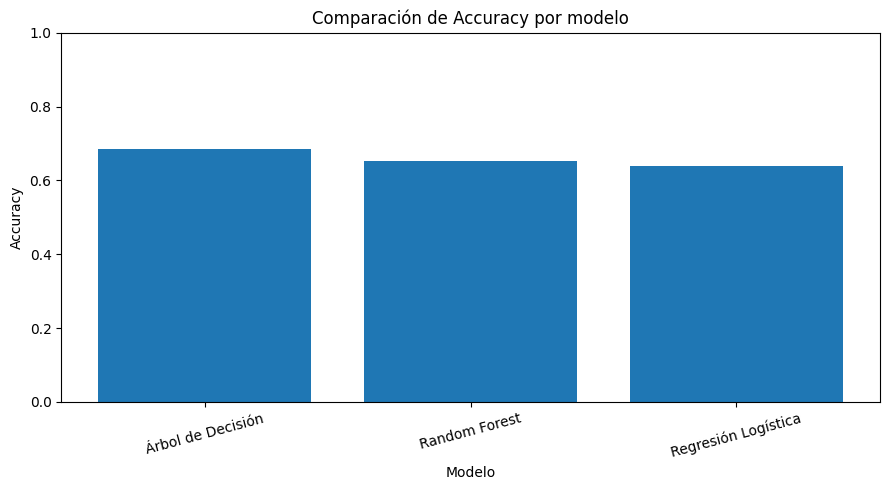

In [40]:
# Paso 6: Gráfica comparativa de Accuracy
orden_accuracy = resultados_df.sort_values("Accuracy", ascending=False)
plt.figure(figsize=(9, 5))
plt.bar(orden_accuracy["Modelo"], orden_accuracy["Accuracy"])
plt.ylim(0, 1)
plt.title("Comparación de Accuracy por modelo")
plt.xlabel("Modelo")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

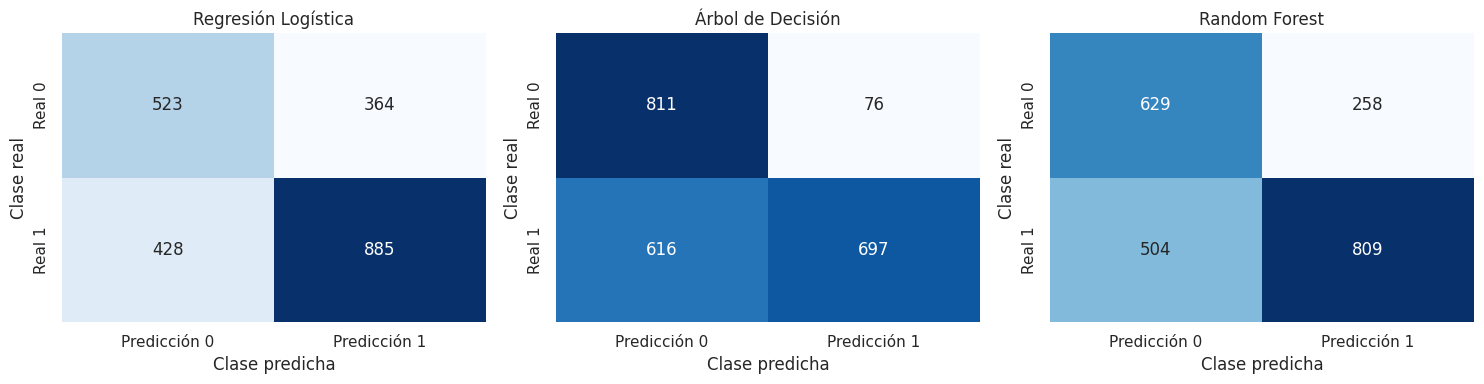

In [ ]:
# Paso 7: Matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nombre, y_pred) in zip(axes, predicciones.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Predicción 0", "Predicción 1"],
        yticklabels=["Real 0", "Real 1"]
    )
    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()